# _**Project of Comp9444**_
**_Named Entity Recognition (NER) for Biomedical Texts using Large Language Models (LLMs)_**

这里需要写一下整个项目的结构（目录）：this notebook contain ......

## **_1. Introduction and Library Imports_**

这里需要说明问题的定义，包括研究的背景和动机，以及需要解决的问题

最后单独介绍一下引用的库（可以不做）


### Reproducible environment

Run this notebook from top to bottom, then save it with its outputs before submission.
Only this `.ipynb` is needed: the notebook downloads NCBI data and BioBERT, generates the
processed/tokenized files, trains E1, and evaluates the selected checkpoint. Internet
access and a writable working directory are required on the first run.

Tested with Python 3.10, PyTorch 2.9.0 and Transformers 5.3.0 in the `cs9517` kernel.
The next cell installs missing packages into the current kernel. If an existing environment
has different versions, use `%pip install torch==2.9.0 transformers==5.3.0` in this notebook,
restart the kernel, and run all cells. GPU results may vary slightly across platforms.


In [ ]:
# Install missing dependencies in this kernel; no repository files are required.
import importlib.util
import importlib.metadata
import subprocess
import sys

required_packages = {
    "torch": "torch==2.9.0",
    "transformers": "transformers==5.3.0",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
}
missing_packages = [package for module, package in required_packages.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])
print("Python:", sys.version.split()[0])
for package in required_packages:
    print(f"{package}: {importlib.metadata.version(package)}")


In [ ]:
# import all the libs here
import numpy as np
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import shutil
import torch

print('all the libs are successfully imported')

# Prefer Apple Metal (MPS), then NVIDIA CUDA, and fall back to CPU.
def select_device():
    mps_backend = getattr(torch.backends, "mps", None)
    if mps_backend is not None and mps_backend.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


device = select_device()
print(f"Using device: {device}")
# Move models and tensor batches to this device with .to(device).


## **_2. Data Loading_**

这里需要说明数据来源，然后解释一下因为数据源下载格式是zip 文件，没办法直接下载到内存里进行操作，只能借助外部文件夹

还需要介绍一下，数据是三个txt文件，数据源已经分好了训练测试和验证

路径使用 pathlib，支持 Windows、macOS 和 Linux；缺失的原始数据会自动下载。

In [2]:
# from one of its subdirectories.
notebook_name = "MedNLP_research.ipynb"
notebook_dir = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / notebook_name).is_file()),
    Path.cwd(),
)
raw_data_dir = notebook_dir / "Dataset" / "RawData"
raw_data_dir.mkdir(parents=True, exist_ok=True)

# download for data scource
datasets = {
    "training": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItrainset_corpus.zip",
        "source_name": "NCBItrainset_corpus.txt",
        "target_name": "NCBI_training.txt",
    },
    "validation": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBIdevelopset_corpus.zip",
        "source_name": "NCBIdevelopset_corpus.txt",
        "target_name": "NCBI_validation.txt",
    },
    "testing": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItestset_corpus.zip",
        "source_name": "NCBItestset_corpus.txt",
        "target_name": "NCBI_testing.txt",
    },
}

for split, dataset_info in datasets.items():
    target_path = raw_data_dir / dataset_info["target_name"]

    if target_path.is_file():
        print(f"{split.capitalize()} set already exists: {target_path}")
        continue

    archive_path = raw_data_dir / Path(dataset_info["url"]).name
    partial_archive_path = archive_path.with_suffix(archive_path.suffix + ".part")
    partial_target_path = target_path.with_suffix(target_path.suffix + ".part")

    print(f"Downloading {split} set...")
    urlretrieve(dataset_info["url"], partial_archive_path)
    partial_archive_path.replace(archive_path)

    # decompress the file
    try:
        with ZipFile(archive_path) as zip_file:
            source_member = next(
                member for member in zip_file.namelist()
                if Path(member).name == dataset_info["source_name"]
            )
            with zip_file.open(source_member) as source, partial_target_path.open("wb") as target:
                shutil.copyfileobj(source, target)
        partial_target_path.replace(target_path)
    finally:
        archive_path.unlink(missing_ok=True)
        partial_target_path.unlink(missing_ok=True)

    print(f"Saved {split} set to: {target_path}")

print("NCBI Disease Corpus download and extraction completed.")

Training set already exists: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_training.txt
Validation set already exists: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_validation.txt
Testing set already exists: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_testing.txt
NCBI Disease Corpus download and extraction completed.


## **_3. Data Processing and Analysis_**

这里要说明处理的流程：

### 3.0 基础处理


In [9]:
import json
from pathlib import Path

# Locate the dataset directories from the project root.
project_dir = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Dataset" / "RawData").is_dir()),
    Path.cwd(),
)
raw_data_dir = project_dir / "Dataset" / "RawData"
processed_data_dir = project_dir / "Dataset" / "ProcessedData"
processed_data_dir.mkdir(parents=True, exist_ok=True)

source_files = (
    "NCBI_training.txt",
    "NCBI_validation.txt",
    "NCBI_testing.txt",
)


def convert_pubtator_to_jsonl(input_path, output_path):
    # Keep every source block, including repeated PMIDs.
    documents = []
    document = None

    with input_path.open(encoding="utf-8") as source:
        for raw_line in source:
            line = raw_line.rstrip("\r\n")
            if not line:
                if document is not None:
                    documents.append(document)
                    document = None
                continue

            if "|t|" in line or "|a|" in line:
                pmid, section, content = line.split("|", 2)
                if section == "t":
                    document = {"pmid": pmid, "title": content, "abstract": "", "entities": []}
                else:
                    document["abstract"] = content
            else:
                fields = line.split("\t")
                if len(fields) < 5:
                    raise ValueError(f"Invalid annotation line: {line}")
                pmid, start, end, mention, entity_type = fields[:5]
                document["entities"].append(
                    {
                        "start": int(start),
                        "end": int(end),
                        "mention": mention,
                        "type": entity_type,
                    }
                )

    if document is not None:
        documents.append(document)

    mismatch_count = 0
    boundary_correction_count = 0
    with output_path.open("w", encoding="utf-8") as destination:
        for document_index, document in enumerate(documents):
            # Corpus offsets use: title + one space + abstract.
            text = document["title"] + " " + document["abstract"]
            entities = []

            for entity in document["entities"]:
                start, end = entity["start"], entity["end"]
                if not 0 <= start < end <= len(text):
                    raise ValueError(
                        f"Invalid offset in PMID {document['pmid']}: [{start}, {end})"
                    )
                if text[start:end] != entity["mention"]:
                    mismatch_count += 1

                # Repair corpus annotations that end inside a word. Such
                # partial-word spans cannot align with WordPiece boundaries.
                original_end = end
                while (
                    end < len(text)
                    and text[end - 1].isalnum()
                    and text[end].isalnum()
                ):
                    end += 1
                boundary_correction_count += int(end != original_end)
                entities.append(
                    {"start": start, "end": end, "type": entity["type"]}
                )

            record = {
                "record_id": f"{input_path.stem}-{document_index:04d}",
                "pmid": document["pmid"],
                "title": document["title"],
                "abstract": document["abstract"],
                "text": text,
                "entities": entities,
            }
            destination.write(json.dumps(record, ensure_ascii=False) + "\n")

    return len(documents), mismatch_count, boundary_correction_count


for source_name in source_files:
    input_path = raw_data_dir / source_name
    output_path = processed_data_dir / Path(source_name).with_suffix(".jsonl").name
    (
        document_count,
        mismatch_count,
        boundary_correction_count,
    ) = convert_pubtator_to_jsonl(input_path, output_path)
    print(
        f"Saved {document_count} documents to: {output_path} "
        f"({mismatch_count} annotation text mismatch(es), "
        f"{boundary_correction_count} boundary correction(s))"
    )

Saved 593 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_training.jsonl (1 annotation text mismatch(es), 2 boundary correction(s))
Saved 100 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_validation.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))
Saved 100 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_testing.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))


数据完成基础清洗之后，接下来进行初步数据分析

### 3.1 数据规模与文档长度


,Documents,Unique PMIDs,Repeated Records,Entity Mentions,Unique Entity Texts,Mean Document Length,Median Document Length,95th Percentile Length,Maximum Document Length
Split,,,,,,,,,
Training,593,592,1,5145,1690,1264.72,1276.0,1909.8,2656
Validation,100,100,0,787,363,1326.40,1272.0,1895.4,2193


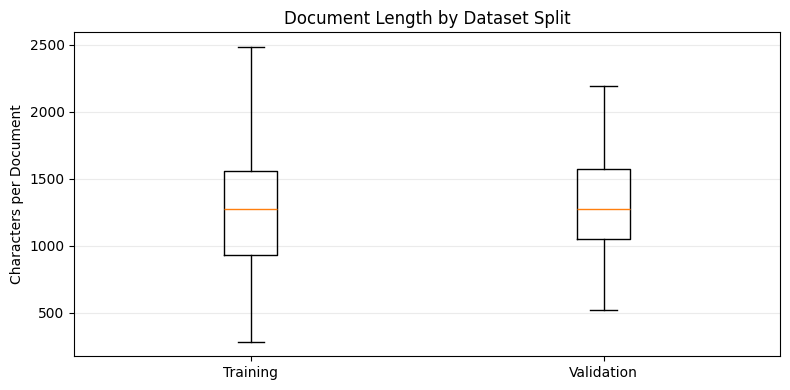

In [10]:
import matplotlib.pyplot as plt
from IPython.display import display

# Load only the training and validation splits for exploratory analysis.
# Keep the testing split untouched to avoid test-set-driven decisions.
split_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
}
records_by_split = {}

for split, file_name in split_files.items():
    file_path = processed_data_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records_by_split[split] = [json.loads(line) for line in source if line.strip()]

# Summarise dataset size and document character lengths.
scale_rows = []
for split, records in records_by_split.items():
    document_lengths = pd.Series([len(record["text"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    unique_pmids = len({record["pmid"] for record in records})

    scale_rows.append({
        "Split": split,
        "Documents": len(records),
        "Unique PMIDs": unique_pmids,
        "Repeated Records": len(records) - unique_pmids,
        "Entity Mentions": len(entity_texts),
        "Unique Entity Texts": len(set(entity_texts)),
        "Mean Document Length": document_lengths.mean(),
        "Median Document Length": document_lengths.median(),
        "95th Percentile Length": document_lengths.quantile(0.95),
        "Maximum Document Length": document_lengths.max(),
    })

scale_summary = pd.DataFrame(scale_rows).set_index("Split")
display(scale_summary.round(2))

# Compare document-length distributions across splits.
plt.figure(figsize=(8, 4))
plt.boxplot(
    [[len(record["text"]) for record in records_by_split[split]] for split in split_files],
    tick_labels=list(split_files),
    showfliers=False,
)
plt.title("Document Length by Dataset Split")
plt.ylabel("Characters per Document")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 3.2 实体分布

,Entities per Document,"Entities per 1,000 Characters",Zero-Entity Documents,Mean Entity Length,Median Entity Length,95th Percentile Entity Length,Maximum Entity Length,Single-Word Entities (%),Multi-Word Entities (%)
Split,,,,,,,,,
Training,8.68,6.86,0,15.19,14.0,37.0,80,46.69,53.31
Validation,7.87,5.93,0,15.74,15.0,37.0,74,42.69,57.31


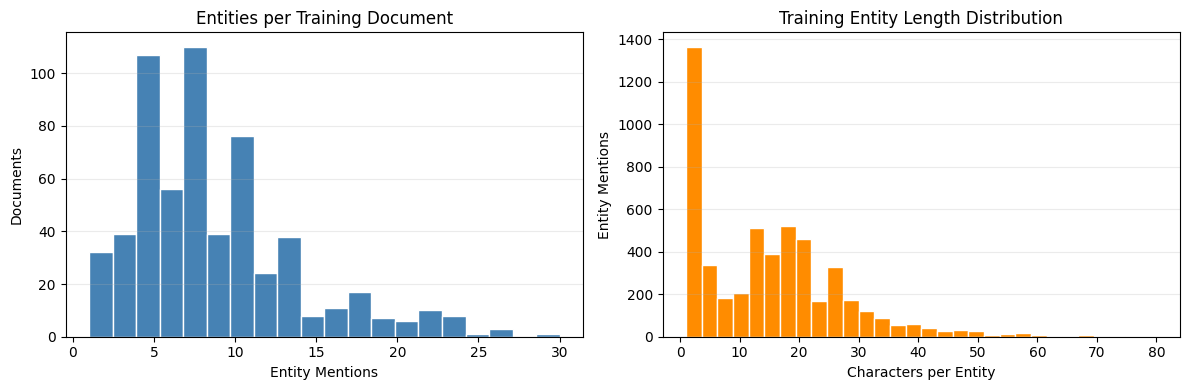

In [11]:
# Summarise entity density and character length for each split.
entity_rows = []
for split, records in records_by_split.items():
    entity_counts = pd.Series([len(record["entities"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    entity_lengths = pd.Series([len(text) for text in entity_texts])
    total_characters = sum(len(record["text"]) for record in records)
    single_word_count = sum(len(text.split()) == 1 for text in entity_texts)

    entity_rows.append({
        "Split": split,
        "Entities per Document": entity_counts.mean(),
        "Entities per 1,000 Characters": len(entity_texts) / total_characters * 1000,
        "Zero-Entity Documents": int((entity_counts == 0).sum()),
        "Mean Entity Length": entity_lengths.mean(),
        "Median Entity Length": entity_lengths.median(),
        "95th Percentile Entity Length": entity_lengths.quantile(0.95),
        "Maximum Entity Length": entity_lengths.max(),
        "Single-Word Entities (%)": single_word_count / len(entity_texts) * 100,
        "Multi-Word Entities (%)": (len(entity_texts) - single_word_count) / len(entity_texts) * 100,
    })

entity_summary = pd.DataFrame(entity_rows).set_index("Split")
display(entity_summary.round(2))

# Plot the main entity distributions in the training set.
training_records = records_by_split["Training"]
training_entity_counts = [len(record["entities"]) for record in training_records]
training_entity_lengths = [
    entity["end"] - entity["start"]
    for record in training_records
    for entity in record["entities"]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(training_entity_counts, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Entities per Training Document")
axes[0].set_xlabel("Entity Mentions")
axes[0].set_ylabel("Documents")

axes[1].hist(training_entity_lengths, bins=30, color="darkorange", edgecolor="white")
axes[1].set_title("Training Entity Length Distribution")
axes[1].set_xlabel("Characters per Entity")
axes[1].set_ylabel("Entity Mentions")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Number of entity types: 4
Entity types: CompositeMention, DiseaseClass, Modifier, SpecificDisease


Split,Training,Validation,Total,Total (%)
Entity Type,,,,
SpecificDisease,2972,412,3384,57.05
Modifier,1289,214,1503,25.34
DiseaseClass,769,126,895,15.09
CompositeMention,115,35,150,2.53


Split,Training (%),Validation (%)
Entity Type,,
CompositeMention,2.24,4.45
DiseaseClass,14.95,16.01
Modifier,25.05,27.19
SpecificDisease,57.76,52.35


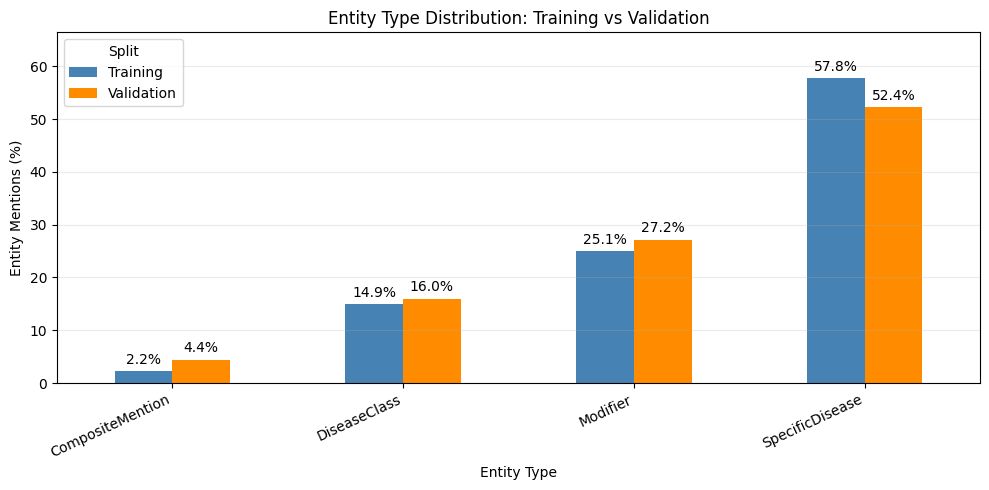

In [12]:
# Analyse entity mention types in the training and validation splits.
missing_type_records = [
    record["record_id"]
    for records in records_by_split.values()
    for record in records
    if any("type" not in entity for entity in record["entities"])
]
if missing_type_records:
    raise ValueError(
        "Entity type is missing from ProcessedData. "
        "Re-run Section 3.0 before this analysis."
    )

entity_types = sorted({
    entity["type"]
    for records in records_by_split.values()
    for record in records
    for entity in record["entities"]
})
print(f"Number of entity types: {len(entity_types)}")
print("Entity types:", ", ".join(entity_types))

type_distribution_rows = []
for split, records in records_by_split.items():
    split_types = [
        entity["type"]
        for record in records
        for entity in record["entities"]
    ]
    split_total = len(split_types)
    for entity_type in entity_types:
        count = split_types.count(entity_type)
        type_distribution_rows.append({
            "Split": split,
            "Entity Type": entity_type,
            "Count": count,
            "Percentage": count / split_total * 100,
        })

type_distribution = pd.DataFrame(type_distribution_rows)
type_count_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Count"
).reindex(columns=list(split_files)).astype(int)
type_count_summary["Total"] = type_count_summary.sum(axis=1)
type_count_summary["Total (%)"] = (
    type_count_summary["Total"]
    / type_count_summary["Total"].sum()
    * 100
)
display(type_count_summary.sort_values("Total", ascending=False).round(2))

type_percentage_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Percentage"
).reindex(columns=list(split_files))
display(type_percentage_summary.round(2).add_suffix(" (%)"))

# Compare within-split percentages so split size does not distort the chart.
plot_percentages = type_percentage_summary.loc[entity_types]
axis = plot_percentages.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
)
for container in axis.containers:
    axis.bar_label(container, fmt="%.1f%%", padding=3)
plt.title("Entity Type Distribution: Training vs Validation")
plt.xlabel("Entity Type")
plt.ylabel("Entity Mentions (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, plot_percentages.to_numpy().max() * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 3.3 tokenized by two methods
#### 3.3.1 BioBERT

In [14]:
from transformers.models.bert.tokenization_bert import BertTokenizerFast

BIOBERT_MODEL = "dmis-lab/biobert-base-cased-v1.1"
# BioBERT v1.1 inherits the BERT-base-cased WordPiece vocabulary.

BIOBERT_TOKENIZER = "google-bert/bert-base-cased"

ENTITY_TYPES = (
    "SpecificDisease",
    "DiseaseClass",
    "CompositeMention",
    "Modifier",
)
BIO_LABELS = ["O"]
for entity_type in ENTITY_TYPES:
    BIO_LABELS.extend([
        f"B-{entity_type}",
        f"I-{entity_type}",
    ])
LABEL2ID = {
    label: label_id for label_id, label in enumerate(BIO_LABELS)
}
ID2LABEL = {
    label_id: label for label, label_id in LABEL2ID.items()
}

dataset_files = (
    "NCBI_training.jsonl",
    "NCBI_validation.jsonl",
    "NCBI_testing.jsonl",
)

biobert_output_dir = (
    project_dir / "Dataset" / "TokenizedData" / "BioBERT"
)
biobert_output_dir.mkdir(parents=True, exist_ok=True)

tokenized_training_path = (
    biobert_output_dir / "NCBI_training.jsonl"
)


def create_typed_bio_tags(offsets, entities, record_id):
    """Align character-level entities with BioBERT WordPieces."""
    bio_tags = ["O"] * len(offsets)

    for entity in sorted(
        entities, key=lambda item: (item["start"], item["end"])
    ):
        required_fields = {"start", "end", "type"}
        if not required_fields.issubset(entity):
            raise ValueError(
                f"Incomplete entity annotation in {record_id}: {entity}"
            )

        entity_start = entity["start"]
        entity_end = entity["end"]
        entity_type = entity["type"]
        if entity_type not in ENTITY_TYPES:
            raise ValueError(
                f"Unknown entity type {entity_type!r} in {record_id}"
            )

        token_indices = [
            token_index
            for token_index, (token_start, token_end) in enumerate(offsets)
            if token_start < entity_end and token_end > entity_start
        ]
        if not token_indices:
            raise ValueError(
                f"Entity [{entity_start}, {entity_end}) has no token "
                f"alignment in {record_id}"
            )

        first_token = token_indices[0]
        last_token = token_indices[-1]
        if (
            offsets[first_token][0] != entity_start
            or offsets[last_token][1] != entity_end
        ):
            raise ValueError(
                f"Entity boundary [{entity_start}, {entity_end}) is not "
                f"aligned with token boundaries in {record_id}"
            )

        if any(bio_tags[index] != "O" for index in token_indices):
            raise ValueError(
                f"Overlapping entities are not supported in {record_id}"
            )

        bio_tags[first_token] = f"B-{entity_type}"
        for token_index in token_indices[1:]:
            bio_tags[token_index] = f"I-{entity_type}"

    return bio_tags


def tokenize_dataset(
    input_path,
    output_path,
    tokenizer,
    model_name,
    tokenizer_name,
    include_gold_labels,
):
    document_count = 0
    token_count = 0

    with input_path.open(encoding="utf-8") as source:
        with output_path.open("w", encoding="utf-8") as destination:
            for line in source:
                if not line.strip():
                    continue

                record = json.loads(line)
                encoded = tokenizer(
                    record["text"],
                    add_special_tokens=False,
                    truncation=False,
                    return_attention_mask=True,
                    return_offsets_mapping=True,
                )
                tokens = tokenizer.convert_ids_to_tokens(
                    encoded["input_ids"]
                )
                offsets = [
                    [start, end]
                    for start, end in encoded["offset_mapping"]
                ]

                has_invalid_offset = any(
                    not 0 <= token_start < token_end
                    <= len(record["text"])
                    for token_start, token_end in offsets
                )
                if has_invalid_offset:
                    raise ValueError(
                        f"Invalid token offset in {record['record_id']}"
                    )

                sequence_lengths = (
                    len(tokens),
                    len(encoded["input_ids"]),
                    len(encoded["attention_mask"]),
                    len(offsets),
                )
                bio_tags = None
                if include_gold_labels:
                    bio_tags = create_typed_bio_tags(
                        offsets,
                        record["entities"],
                        record["record_id"],
                    )
                    sequence_lengths += (len(bio_tags),)
                if len(set(sequence_lengths)) != 1:
                    raise ValueError(
                        f"Token alignment failed for {record['record_id']}"
                    )

                tokenized_record = {
                    "record_id": record["record_id"],
                    "pmid": record["pmid"],
                    "model": model_name,
                    "tokenizer": tokenizer_name,
                    "text": record["text"],
                    "entities": [],
                    "tokens": tokens,
                    "input_ids": encoded["input_ids"],
                    "attention_mask": encoded["attention_mask"],
                    "offset_mapping": offsets,
                    "bio_tags": [],
                }
                if include_gold_labels:
                    tokenized_record["entities"] = record["entities"]
                    tokenized_record["bio_tags"] = bio_tags
                destination.write(
                    json.dumps(tokenized_record, ensure_ascii=False)
                    + "\n"
                )
                document_count += 1
                token_count += len(tokens)

    return document_count, token_count


# A fast tokenizer is required to return character offsets.
biobert_tokenizer = BertTokenizerFast.from_pretrained(
    BIOBERT_TOKENIZER
)
if not biobert_tokenizer.is_fast:
    raise RuntimeError(
        "BioBERT fast tokenizer is required for offset mapping."
    )

for file_name in dataset_files:
    input_path = processed_data_dir / file_name
    output_path = biobert_output_dir / file_name
    include_gold_labels = file_name == "NCBI_training.jsonl"
    document_count, token_count = tokenize_dataset(
        input_path,
        output_path,
        biobert_tokenizer,
        BIOBERT_MODEL,
        BIOBERT_TOKENIZER,
        include_gold_labels,
    )
    print(
        f"Saved {document_count} BioBERT-tokenized documents to: "
        f"{output_path}"
    )
    print(f"Total WordPiece tokens: {token_count}")
    print(
        "Gold entities and BIO tags: "
        + ("included" if include_gold_labels else "masked")
    )

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (762 > 512). Running this sequence through the model will result in indexing errors


Saved 593 BioBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\BioBERT\NCBI_training.jsonl
Total WordPiece tokens: 184552
Gold entities and BIO tags: included
Saved 100 BioBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\BioBERT\NCBI_validation.jsonl
Total WordPiece tokens: 32132
Gold entities and BIO tags: masked
Saved 100 BioBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\BioBERT\NCBI_testing.jsonl
Total WordPiece tokens: 33092
Gold entities and BIO tags: masked


#### 3.3.2 BioBERT 分词结果分析

,Documents,Total WordPieces,Mean WordPieces,Median WordPieces,95th Percentile,Maximum WordPieces,Documents > 510
Split,,,,,,,
Training,593,184552,311.22,307.0,492.8,762,24
Validation,100,32132,321.32,312.0,485.3,529,4
Testing,100,33092,330.92,316.5,496.1,684,3


,Count,Mean,Median,Minimum,95th Percentile,Maximum
Measurement,,,,,,
WordPieces per document,593,311.22,307.0,74,492.8,762
Characters per WordPiece,184552,3.45,3.0,1,9.0,16
WordPieces per entity,5145,4.76,4.0,1,11.0,33


,Content WordPiece Limit,Documents Exceeding Limit,Documents Exceeding Limit (%)
Model Max Length,,,
128,126,577,97.30
256,254,396,66.78
512,510,24,4.05


,Count,Percentage
Metric,,
Single-WordPiece entities,243,4.72
Multi-WordPiece entities,4902,95.28
Boundary-aligned entities,5145,100.00
Boundary-unaligned entities,0,0.00


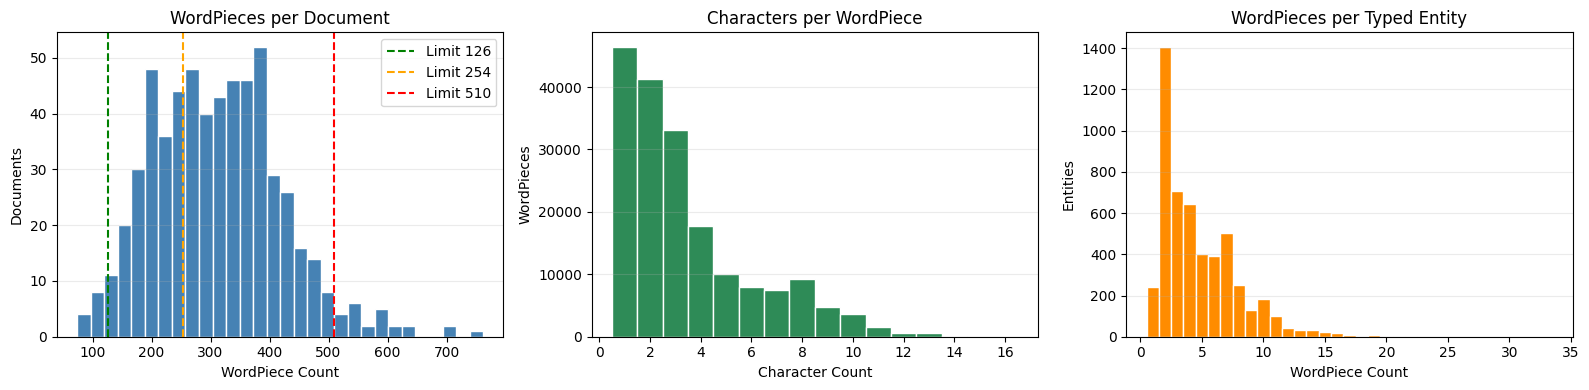

,Count,Percentage
Label,,
O,160047,86.722
B-SpecificDisease,2972,1.610
I-SpecificDisease,12461,6.752
B-DiseaseClass,769,0.417
I-DiseaseClass,2919,1.582
B-CompositeMention,115,0.062
I-CompositeMention,946,0.513
B-Modifier,1289,0.698
I-Modifier,3034,1.644


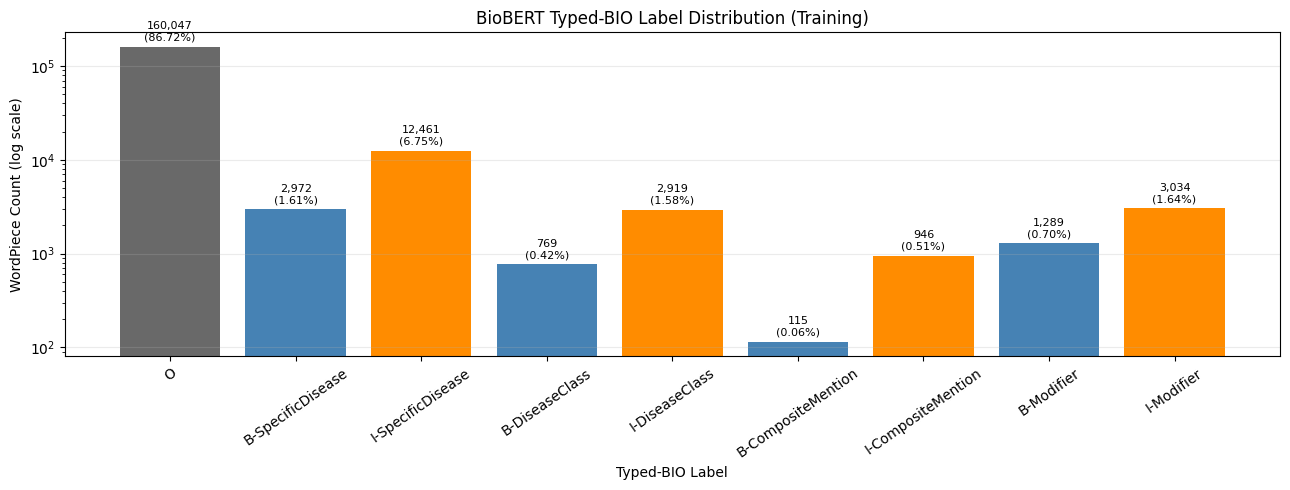

In [15]:
from collections import Counter

# Load all BioBERT-tokenized splits and validate the shared JSONL schema.
biobert_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
    "Testing": "NCBI_testing.jsonl",
}
biobert_records_by_split = {}
required_tokenized_fields = {
    "record_id",
    "pmid",
    "model",
    "tokenizer",
    "text",
    "entities",
    "tokens",
    "input_ids",
    "attention_mask",
    "offset_mapping",
    "bio_tags",
}

for split, file_name in biobert_files.items():
    file_path = biobert_output_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records = [
            json.loads(line) for line in source if line.strip()
        ]

    for record in records:
        missing_fields = required_tokenized_fields - set(record)
        if missing_fields:
            raise ValueError(
                f"Missing fields {sorted(missing_fields)} in "
                f"{record.get('record_id', file_name)}"
            )
        sequence_lengths = {
            len(record["tokens"]),
            len(record["input_ids"]),
            len(record["attention_mask"]),
            len(record["offset_mapping"]),
        }
        if len(sequence_lengths) != 1:
            raise ValueError(
                f"Token sequence mismatch in {record['record_id']}"
            )

        if split == "Training":
            if len(record["bio_tags"]) != len(record["tokens"]):
                raise ValueError(
                    f"BIO alignment mismatch in {record['record_id']}"
                )
        elif record["entities"] or record["bio_tags"]:
            raise ValueError(
                f"Gold labels are not masked in {record['record_id']}"
            )

    biobert_records_by_split[split] = records

# Preserve the original analysis scope: descriptive statistics use Training.
biobert_records = biobert_records_by_split["Training"]

# Summarise tokenization volume for every split without using masked gold.
split_token_rows = []
for split, records in biobert_records_by_split.items():
    split_token_counts = pd.Series([
        len(record["tokens"]) for record in records
    ])
    split_token_rows.append({
        "Split": split,
        "Documents": len(records),
        "Total WordPieces": int(split_token_counts.sum()),
        "Mean WordPieces": split_token_counts.mean(),
        "Median WordPieces": split_token_counts.median(),
        "95th Percentile": split_token_counts.quantile(0.95),
        "Maximum WordPieces": int(split_token_counts.max()),
        "Documents > 510": int((split_token_counts > 510).sum()),
    })
split_token_summary = pd.DataFrame(split_token_rows).set_index("Split")
display(split_token_summary.round(2))

document_token_counts = [
    len(record["tokens"]) for record in biobert_records
]
token_character_lengths = [
    token_end - token_start
    for record in biobert_records
    for token_start, token_end in record["offset_mapping"]
]

entity_wordpiece_counts = []
boundary_aligned_entities = 0

for record in biobert_records:
    offsets = record["offset_mapping"]
    token_starts = {token_start for token_start, _ in offsets}
    token_ends = {token_end for _, token_end in offsets}

    for entity in record["entities"]:
        wordpiece_count = sum(
            token_start < entity["end"]
            and token_end > entity["start"]
            for token_start, token_end in offsets
        )
        entity_wordpiece_counts.append(wordpiece_count)

        is_boundary_aligned = (
            entity["start"] in token_starts
            and entity["end"] in token_ends
        )
        boundary_aligned_entities += int(is_boundary_aligned)


def describe_values(name, values):
    values = pd.Series(values)
    return {
        "Measurement": name,
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "95th Percentile": values.quantile(0.95),
        "Maximum": values.max(),
    }


token_statistics = pd.DataFrame([
    describe_values("WordPieces per document", document_token_counts),
    describe_values("Characters per WordPiece", token_character_lengths),
    describe_values("WordPieces per entity", entity_wordpiece_counts),
]).set_index("Measurement")
display(token_statistics.round(2))

# Reserve two positions for [CLS] and [SEP].
capacity_rows = []
for model_max_length in (128, 256, 512):
    content_limit = model_max_length - 2
    exceeding_count = sum(
        count > content_limit for count in document_token_counts
    )
    capacity_rows.append({
        "Model Max Length": model_max_length,
        "Content WordPiece Limit": content_limit,
        "Documents Exceeding Limit": exceeding_count,
        "Documents Exceeding Limit (%)": (
            exceeding_count / len(document_token_counts) * 100
        ),
    })

capacity_summary = pd.DataFrame(capacity_rows).set_index(
    "Model Max Length"
)
display(capacity_summary.round(2))

total_entities = len(entity_wordpiece_counts)
single_wordpiece_entities = sum(
    count == 1 for count in entity_wordpiece_counts
)
entity_alignment_summary = pd.DataFrame({
    "Metric": [
        "Single-WordPiece entities",
        "Multi-WordPiece entities",
        "Boundary-aligned entities",
        "Boundary-unaligned entities",
    ],
    "Count": [
        single_wordpiece_entities,
        total_entities - single_wordpiece_entities,
        boundary_aligned_entities,
        total_entities - boundary_aligned_entities,
    ],
}).set_index("Metric")
entity_alignment_summary["Percentage"] = (
    entity_alignment_summary["Count"] / total_entities * 100
)
display(entity_alignment_summary.round(2))

# Plot document, token, and entity tokenization distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    document_token_counts,
    bins=30,
    color="steelblue",
    edgecolor="white",
)
for limit, color in zip((126, 254, 510), ("green", "orange", "red")):
    axes[0].axvline(
        limit,
        color=color,
        linestyle="--",
        label=f"Limit {limit}",
    )
axes[0].set_title("WordPieces per Document")
axes[0].set_xlabel("WordPiece Count")
axes[0].set_ylabel("Documents")
axes[0].legend()

token_length_bins = np.arange(
    0.5, max(token_character_lengths) + 1.5, 1
)
axes[1].hist(
    token_character_lengths,
    bins=token_length_bins,
    color="seagreen",
    edgecolor="white",
)
axes[1].set_title("Characters per WordPiece")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("WordPieces")

entity_piece_bins = np.arange(
    0.5, max(entity_wordpiece_counts) + 1.5, 1
)
axes[2].hist(
    entity_wordpiece_counts,
    bins=entity_piece_bins,
    color="darkorange",
    edgecolor="white",
)
axes[2].set_title("WordPieces per Typed Entity")
axes[2].set_xlabel("WordPiece Count")
axes[2].set_ylabel("Entities")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# Analyse the 4 * 2 + 1 typed-BIO labels in the training split only.
training_label_counts = Counter(
    tag
    for record in biobert_records
    for tag in record["bio_tags"]
)
unknown_labels = set(training_label_counts) - set(BIO_LABELS)
if unknown_labels:
    raise ValueError(
        f"Unknown BIO labels found: {sorted(unknown_labels)}"
    )

label_distribution = pd.DataFrame({
    "Label": BIO_LABELS,
    "Count": [training_label_counts[label] for label in BIO_LABELS],
})
label_distribution["Percentage"] = (
    label_distribution["Count"]
    / label_distribution["Count"].sum()
    * 100
)
display(label_distribution.set_index("Label").round(3))

label_colors = [
    "dimgray"
    if label == "O"
    else "steelblue"
    if label.startswith("B-")
    else "darkorange"
    for label in label_distribution["Label"]
]
fig, axis = plt.subplots(figsize=(13, 5))
bars = axis.bar(
    label_distribution["Label"],
    label_distribution["Count"],
    color=label_colors,
)
axis.set_yscale("log")
axis.bar_label(
    bars,
    labels=[
        f"{count:,}\n({percentage:.2f}%)"
        for count, percentage in zip(
            label_distribution["Count"],
            label_distribution["Percentage"],
        )
    ],
    padding=3,
    fontsize=8,
)
axis.set_title("BioBERT Typed-BIO Label Distribution (Training)")
axis.set_xlabel("Typed-BIO Label")
axis.set_ylabel("WordPiece Count (log scale)")
axis.tick_params(axis="x", rotation=35)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## **_4. Standardized Testing_**

In [ ]:
from collections import Counter
import json
from pathlib import Path

import pandas as pd

EVALUATION_ENTITY_TYPES = (
    "SpecificDisease",
    "DiseaseClass",
    "CompositeMention",
    "Modifier",
)


def load_jsonl_records(file_path):
    records = []
    with Path(file_path).open(encoding="utf-8") as source:
        for line_number, line in enumerate(source, start=1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as error:
                raise ValueError(
                    f"Invalid JSON on line {line_number}: {file_path}"
                ) from error
    return records


def index_records(records, source_name):
    indexed = {}
    for record in records:
        record_id = record.get("record_id")
        if not isinstance(record_id, str) or not record_id:
            raise ValueError(f"Missing record_id in {source_name}")
        if record_id in indexed:
            raise ValueError(
                f"Duplicate record_id {record_id} in {source_name}"
            )
        indexed[record_id] = record
    return indexed


def validate_entity(entity, record_id, text_length):
    if not isinstance(entity, dict):
        raise TypeError(f"Entity in {record_id} must be a dictionary")
    if set(entity) != {"start", "end", "type"}:
        raise ValueError(
            f"Entity in {record_id} must contain only start, end, and type"
        )

    start, end = entity["start"], entity["end"]
    entity_type = entity["type"]
    valid_offsets = (
        isinstance(start, int)
        and not isinstance(start, bool)
        and isinstance(end, int)
        and not isinstance(end, bool)
    )
    if not valid_offsets or not 0 <= start < end <= text_length:
        raise ValueError(
            f"Invalid span [{start}, {end}) in {record_id}"
        )
    if entity_type not in EVALUATION_ENTITY_TYPES:
        raise ValueError(
            f"Invalid entity type {entity_type!r} in {record_id}"
        )
    return start, end, entity_type


def validate_prediction(prediction, gold_record):
    required_fields = {"record_id", "pmid", "entities"}
    if set(prediction) != required_fields:
        raise ValueError(
            f"Prediction {prediction.get('record_id')} must contain only "
            "record_id, pmid, and entities"
        )
    record_id = prediction["record_id"]
    if prediction["pmid"] != gold_record["pmid"]:
        raise ValueError(f"PMID mismatch for {record_id}")
    if not isinstance(prediction["entities"], list):
        raise ValueError(f"entities must be a list in {record_id}")

    text_length = len(gold_record["text"])
    entities = [
        validate_entity(entity, record_id, text_length)
        for entity in prediction["entities"]
    ]
    if entities != sorted(entities):
        raise ValueError(f"Entities are not sorted in {record_id}")
    if len(entities) != len(set(entities)):
        raise ValueError(f"Duplicate entities in {record_id}")

    spans = [(start, end) for start, end, _ in entities]
    if len(spans) != len(set(spans)):
        raise ValueError(
            f"A span has multiple predicted types in {record_id}"
        )
    return entities


def calculate_prf(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )
    return {
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


def set_counts(gold_values, predicted_values):
    return (
        len(gold_values & predicted_values),
        len(predicted_values - gold_values),
        len(gold_values - predicted_values),
    )


def boundary_counts(gold_values, predicted_values):
    gold_counter = Counter(gold_values)
    predicted_counter = Counter(predicted_values)
    return (
        sum((gold_counter & predicted_counter).values()),
        sum((predicted_counter - gold_counter).values()),
        sum((gold_counter - predicted_counter).values()),
    )


def spans_to_characters(spans):
    characters = set()
    for start, end in spans:
        characters.update(range(start, end))
    return characters


def add_counts(total, current):
    for index, value in enumerate(current):
        total[index] += value


def evaluate_standardized_records(gold_records, prediction_records):
    gold_by_id = index_records(gold_records, "gold records")
    pred_by_id = index_records(prediction_records, "predictions")
    missing = sorted(set(gold_by_id) - set(pred_by_id))
    extra = sorted(set(pred_by_id) - set(gold_by_id))
    if missing or extra:
        raise ValueError(
            f"Record mismatch: missing={missing}, extra={extra}"
        )

    typed_total = [0, 0, 0]
    span_only_total = [0, 0, 0]
    start_total = [0, 0, 0]
    end_total = [0, 0, 0]
    character_total = [0, 0, 0]
    per_type_totals = {
        entity_type: [0, 0, 0]
        for entity_type in EVALUATION_ENTITY_TYPES
    }
    type_confusion = {
        gold_type: {pred_type: 0 for pred_type in EVALUATION_ENTITY_TYPES}
        for gold_type in EVALUATION_ENTITY_TYPES
    }
    matched_span_count = 0
    correct_type_count = 0
    gold_entity_count = 0
    predicted_entity_count = 0

    for record_id, gold_record in gold_by_id.items():
        text_length = len(gold_record["text"])
        gold_entities = [
            validate_entity(entity, record_id, text_length)
            for entity in gold_record["entities"]
        ]
        predicted_entities = validate_prediction(
            pred_by_id[record_id], gold_record
        )

        gold_spans = [(start, end) for start, end, _ in gold_entities]
        predicted_spans = [
            (start, end) for start, end, _ in predicted_entities
        ]
        if len(gold_spans) != len(set(gold_spans)):
            raise ValueError(
                f"A gold span has multiple types in {record_id}"
            )

        gold_entity_count += len(gold_entities)
        predicted_entity_count += len(predicted_entities)
        gold_entity_set = set(gold_entities)
        predicted_entity_set = set(predicted_entities)
        gold_span_set = set(gold_spans)
        predicted_span_set = set(predicted_spans)

        add_counts(
            typed_total,
            set_counts(gold_entity_set, predicted_entity_set),
        )
        add_counts(
            span_only_total,
            set_counts(gold_span_set, predicted_span_set),
        )

        for entity_type in EVALUATION_ENTITY_TYPES:
            gold_for_type = {
                entity for entity in gold_entity_set
                if entity[2] == entity_type
            }
            predicted_for_type = {
                entity for entity in predicted_entity_set
                if entity[2] == entity_type
            }
            add_counts(
                per_type_totals[entity_type],
                set_counts(gold_for_type, predicted_for_type),
            )

        gold_type_by_span = {
            (start, end): entity_type
            for start, end, entity_type in gold_entities
        }
        predicted_type_by_span = {
            (start, end): entity_type
            for start, end, entity_type in predicted_entities
        }
        for span in gold_span_set & predicted_span_set:
            gold_type = gold_type_by_span[span]
            predicted_type = predicted_type_by_span[span]
            type_confusion[gold_type][predicted_type] += 1
            matched_span_count += 1
            correct_type_count += int(gold_type == predicted_type)

        add_counts(
            start_total,
            boundary_counts(
                [start for start, _ in gold_spans],
                [start for start, _ in predicted_spans],
            ),
        )
        add_counts(
            end_total,
            boundary_counts(
                [end for _, end in gold_spans],
                [end for _, end in predicted_spans],
            ),
        )
        add_counts(
            character_total,
            set_counts(
                spans_to_characters(gold_spans),
                spans_to_characters(predicted_spans),
            ),
        )

    per_type = {}
    for entity_type, counts in per_type_totals.items():
        values = calculate_prf(*counts)
        values["support"] = counts[0] + counts[2]
        values["predicted_count"] = counts[0] + counts[1]
        per_type[entity_type] = values

    typed_macro = {
        metric: sum(values[metric] for values in per_type.values())
        / len(EVALUATION_ENTITY_TYPES)
        for metric in ("precision", "recall", "f1")
    }
    wrong_type_count = matched_span_count - correct_type_count

    return {
        "averaging": "micro",
        "document_count": len(gold_by_id),
        "gold_entity_count": gold_entity_count,
        "predicted_entity_count": predicted_entity_count,
        "typed_exact": calculate_prf(*typed_total),
        "typed_macro": typed_macro,
        "per_type": per_type,
        "span_only_exact": calculate_prf(*span_only_total),
        "exact_span_type": {
            "matched_span_count": matched_span_count,
            "correct_type_count": correct_type_count,
            "wrong_type_count": wrong_type_count,
            "accuracy": (
                correct_type_count / matched_span_count
                if matched_span_count
                else 0.0
            ),
        },
        "type_confusion_matrix": type_confusion,
        "start_boundary": calculate_prf(*start_total),
        "end_boundary": calculate_prf(*end_total),
        "character_overlap": calculate_prf(*character_total),
    }


def evaluate_model_predictions(prediction_records, split):
    # Select the gold file while keeping one shared public evaluation entry point.
    if not isinstance(prediction_records, list):
        raise TypeError("prediction_records must be a list of dictionaries")
    if not all(isinstance(record, dict) for record in prediction_records):
        raise TypeError("Every prediction record must be a dictionary")

    if not isinstance(split, str):
        raise TypeError("split must be a string: 'validation' or 'test'")

    split_name = split.strip().lower()
    gold_file_names = {
        "validation": "NCBI_validation.jsonl",
        "test": "NCBI_testing.jsonl",
    }
    if split_name not in gold_file_names:
        raise ValueError("split must be 'validation' or 'test'")

    current_directory = Path.cwd().resolve()
    project_root = next(
        (
            path
            for path in (current_directory, *current_directory.parents)
            if (path / "Dataset" / "ProcessedData").is_dir()
        ),
        None,
    )
    if project_root is None:
        raise FileNotFoundError(
            "Could not locate Dataset/ProcessedData from the current directory"
        )

    gold_path = (
        project_root
        / "Dataset"
        / "ProcessedData"
        / gold_file_names[split_name]
    )
    return evaluate_standardized_records(
        load_jsonl_records(gold_path),
        prediction_records,
    )


def metrics_to_table(metrics):
    rows = []

    def append_prf_row(metric_name, values):
        rows.append({
            "Metric": metric_name,
            "TP": values.get("true_positives"),
            "FP": values.get("false_positives"),
            "FN": values.get("false_negatives"),
            "Precision": values["precision"],
            "Recall": values["recall"],
            "F1": values["f1"],
        })

    append_prf_row("Typed exact (micro)", metrics["typed_exact"])
    append_prf_row("Typed macro", metrics["typed_macro"])
    for entity_type in EVALUATION_ENTITY_TYPES:
        append_prf_row(
            f"Typed: {entity_type}",
            metrics["per_type"][entity_type],
        )
    append_prf_row("Span-only exact", metrics["span_only_exact"])
    append_prf_row("Start boundary", metrics["start_boundary"])
    append_prf_row("End boundary", metrics["end_boundary"])
    append_prf_row("Character overlap", metrics["character_overlap"])
    return pd.DataFrame(rows).set_index("Metric")


def type_confusion_to_table(metrics):
    table = pd.DataFrame.from_dict(
        metrics["type_confusion_matrix"], orient="index"
    )
    return table.reindex(
        index=EVALUATION_ENTITY_TYPES,
        columns=EVALUATION_ENTITY_TYPES,
        fill_value=0,
    ).rename_axis("Gold type").rename_axis("Predicted type", axis=1)


def save_metrics(metrics, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", encoding="utf-8") as destination:
        json.dump(metrics, destination, indent=2, ensure_ascii=False)


# Example usage after the model has produced prediction_records in memory:
# metrics = evaluate_model_predictions(prediction_records, "test")
# display(metrics_to_table(metrics).round(4))
# display(type_confusion_to_table(metrics))
# save_metrics(
#     metrics,
#     project_dir / "results" / "B1_test_metrics.json",
# )


print("Standardized evaluation functions are ready.")

## **_5. E1 — Head-only BioBERT baseline_**

This cell implements E1 entirely inside the notebook. The external `e1_head_only.py`
is retained for development but is **not required for submission or execution**.
Run Sections 1–4 first to download, preprocess, tokenize and define the shared evaluator.

The entire BioBERT backbone is frozen; only the nine-class typed-BIO head (6,921 parameters)
is trained. Each learning rate (`1e-4`, `5e-4`, `1e-3`) starts independently with seed 42.
The budget is 30 epochs, batch size 8, AdamW, weight decay 0.01 and gradient clipping 1.0.
Early stopping uses validation typed exact-span micro F1 with patience 3. Device priority
is Metal (MPS), CUDA, then CPU. Windows contain at most 512 tokens with 64-token overlap;
overlap tokens are supervised once, logits are averaged at global token positions,
and a single document-level BIO decoding pass follows. Illegal `I` transitions are
counted and repaired as `B`.

Validation selects the learning rate and checkpoint; only then is the official Test
evaluated. Outputs include candidate scores, strict entity metrics, per-type scores,
type confusion, invalid transitions and learning curves. Every execution uses a new
output directory, so running this cell again starts a fresh experiment.

For a quick pipeline check set `E1_SMOKE_DOCS = 2`. Restore **`None`** before the final
run and submission. Single-seed results do not estimate uncertainty; neither the
30-epoch cap nor early stopping guarantees convergence. MPS peak GPU memory is recorded
as `None` because this implementation has no equivalent CUDA peak-memory statistic.

Development reference (seed 42, MPS): selected LR `1e-3`, epoch 21; Validation micro F1
41.84%, Test micro F1 43.39%. These are reference results; the cell calculates its own
metrics rather than hard-coding them. Runtime and results can vary by environment.


## **_5. E1 — 仅训练头部（Head-only）的 BioBERT 基线模型_**

本单元在 Notebook 内部完整实现了 E1。外部的 `e1_head_only.py` 文件仅供开发阶段参考，**提交或执行时无需使用**。请先运行第 1 至 4 节，完成数据下载、预处理、分词以及共享评估器的定义。

在此模型中，整个 BioBERT 主干网络（backbone）被冻结；仅训练九分类的 BIO 头部（包含 6,921 个参数）。针对每种学习率（`1e-4`、`5e-4`、`1e-3`），均使用随机种子 42 独立进行训练。训练配置包括：最多 30 个 epoch，批次大小（batch size）为 8，采用 AdamW 优化器，权重衰减（weight decay）设为 0.01，梯度裁剪（gradient clipping）设为 1.0。训练过程中采用“提前停止”（early stopping）策略，依据验证集上的“带类型精确跨度（typed exact-span）微观 F1 分数”进行判断，容忍度（patience）设为 3。设备优先级顺序为：Metal (MPS) > CUDA > CPU。输入窗口最大长度为 512 个 token，窗口间重叠长度为 64 个 token；重叠部分的 token 仅参与一次监督训练，在全局 token 位置上对模型输出（logits）取平均值，最后进行文档级的 BIO 解码。若出现不合法的 `I` 标签转移（即 BIO 序列中不符合规范的转换），系统会将其统计并修正为 `B` 标签。

通过验证集选择最佳学习率和模型检查点（checkpoint）后，再对正式测试集进行评估。输出结果包括：候选得分、严格实体指标、各类型得分、类型混淆情况、非法标签转移统计以及学习曲线。每次执行都会创建新的输出目录，因此重复运行此单元将开启全新的实验。

若需快速验证流程，可设置 `E1_SMOKE_DOCS = 2`；在最终运行及提交前，请将其恢复为 **`None`**。由于仅使用单一随机种子，结果无法反映不确定性；此外，30 个 epoch 的上限或提前停止机制均不能保证模型已完全收敛。关于 MPS 的峰值 GPU 内存占用，此处记录为 `None`，因为该实现方式中没有与 CUDA 峰值内存统计相对应的指标。

开发参考（随机种子 42，MPS）：选定的学习率为 `1e-3`，最佳 epoch 为 21。验证集 Micro F1 为 41.84%，测试集 Micro F1 为 43.39%。以上结果仅供参考；相关指标由代码单元（cell）自行计算得出，而非硬编码。运行时间和结果可能会因环境不同而有所差异。

In [ ]:
# E1 is implemented inline: no import, %run, or shell call to e1_head_only.py.
# Requires the data preparation and Standardized Testing cells above.
import gc
from datetime import datetime, timezone

E1_PROJECT_DIR = Path(project_dir).resolve()
E1_MAX_EPOCHS = 30
E1_LEARNING_RATES = ("1e-4", "5e-4", "1e-3")
E1_SEED = 42
E1_TRAINING_CONFIG = {
    "batch_size": 8,
    "weight_decay": 0.01,
    "patience": 3,
    "max_length": 512,
    "stride": 64,
}
E1_SMOKE_DOCS = None  # Set to 2 for a pipeline check; restore None for formal results.
E1_RUN_DIR = E1_PROJECT_DIR / "results" / "E1_notebook" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")

# Reuse BIO_LABELS / LABEL2ID / ID2LABEL from tokenization and select_device from Section 1.
assert tuple(ENTITY_TYPES) == EVALUATION_ENTITY_TYPES


def make_windows(records, tokenizer, max_length, stride):
    """Keep full-document token indices; supervise overlap tokens only once."""
    capacity = max_length - 2
    if not 0 <= stride < capacity:
        raise ValueError('stride must be between 0 and max_length - 3')
    windows = []
    for doc, record in enumerate(records):
        ids, tags = record['input_ids'], record['bio_tags']
        if not len(ids) == len(tags) == len(record['offset_mapping']):
            raise ValueError(f"Unaligned tokens: {record['record_id']}")
        covered = 0
        for start in range(0, len(ids), capacity - stride):
            end = min(start + capacity, len(ids))
            labels = [LABEL2ID[tag] if i >= covered else -100
                      for i, tag in enumerate(tags[start:end], start)]
            windows.append({'doc': doc, 'start': start, 'end': end,
                            'input_ids': [tokenizer.cls_token_id] + ids[start:end] + [tokenizer.sep_token_id],
                            'labels': [-100] + labels + [-100]})
            covered = end
            if end == len(ids):
                break
    return windows


def decode_document(record, tag_ids):
    """Repair illegal I transitions as B; report their original count."""
    entities, active, illegal = [], None, 0
    for (start, end), label in zip(record['offset_mapping'], tag_ids):
        tag = BIO_LABELS[int(label)]
        prefix, kind = ('O', None) if tag == 'O' else tag.split('-', 1)
        if prefix == 'I' and (active is None or active['type'] != kind):
            illegal += 1
            prefix = 'B'
        if prefix != 'I' and active is not None:
            entities.append(active)
            active = None
        if prefix == 'B':
            active = {'start': start, 'end': end, 'type': kind}
        elif prefix == 'I':
            active['end'] = end
    if active is not None:
        entities.append(active)
    return {'record_id': record['record_id'], 'pmid': record['pmid'], 'entities': entities}, illegal


def run_e1(*, output_dir, learning_rate=5e-4, epochs=30, seed=42,
           batch_size=8, weight_decay=0.01, patience=3, max_length=512,
           stride=64, limit_docs=None, evaluate_checkpoint=None,
           model_name=BIOBERT_MODEL):
    import random
    import time
    from torch.utils.data import DataLoader
    from transformers import AutoModelForTokenClassification, AutoTokenizer, BertConfig

    data_dir = Path(biobert_output_dir)
    gold_dir = Path(processed_data_dir)
    output_dir = Path(output_dir)
    if evaluate_checkpoint is not None:
        evaluate_checkpoint = Path(evaluate_checkpoint)
    if min(epochs, batch_size, patience) < 1 or (limit_docs is not None and limit_docs < 1):
        raise ValueError("epochs, batch_size, patience and limit_docs must be positive")
    if output_dir.exists() and any(output_dir.iterdir()):
        raise ValueError("output_dir must be empty; choose a new directory for each run")
    output_dir.mkdir(parents=True, exist_ok=True)
    random.seed(seed)
    torch.manual_seed(seed)
    device = select_device()
    print(f'Device: {device}', flush=True)
    tokenizer = AutoTokenizer.from_pretrained('google-bert/bert-base-cased', use_fast=True)
    # The original BioBERT config predates the model_type field required by Transformers 5.
    model_config = BertConfig.from_pretrained(
        model_name, num_labels=len(BIO_LABELS), id2label=ID2LABEL,
        label2id=LABEL2ID)
    model = AutoModelForTokenClassification.from_pretrained(evaluate_checkpoint or model_name, **({} if evaluate_checkpoint else {'config': model_config}))
    if evaluate_checkpoint and model.config.id2label != ID2LABEL:
        raise ValueError('Checkpoint label mapping differs from E1')
    if max_length > model.config.max_position_embeddings:
        raise ValueError('max_length exceeds model position embeddings')
    for parameter in model.base_model.parameters():
        parameter.requires_grad = False
    model.to(device)
    trainable = [p for p in model.parameters() if p.requires_grad]
    assert {name for name, p in model.named_parameters() if p.requires_grad} == {'classifier.weight', 'classifier.bias'}
    optimizer = torch.optim.AdamW(trainable, lr=learning_rate, weight_decay=weight_decay)

    def load_split(name):
        records = load_jsonl_records(data_dir / f'NCBI_{name}.jsonl')
        if limit_docs:
            records = records[:limit_docs]
        for record in records:
            if record.get('model') != model_name:
                raise ValueError('Tokenized data model differs from --model')
            # Validate that cached token IDs still match the exact full text.
            encoded = tokenizer(record['text'], add_special_tokens=False, return_offsets_mapping=True)
            if encoded['input_ids'] != record['input_ids'] or [list(x) for x in encoded['offset_mapping']] != record['offset_mapping']:
                raise ValueError(f"Tokenizer mismatch: {record['record_id']}")
        if name != 'training':
            # Validation/Test caches deliberately hide gold; use the evaluation source.
            gold = index_records(load_jsonl_records(gold_dir / f'NCBI_{name}.jsonl'), name)
            for record in records:
                reference = gold[record['record_id']]
                if reference['pmid'] != record['pmid'] or reference['text'] != record['text']:
                    raise ValueError('Gold and tokenized documents differ')
                record['entities'] = reference['entities']
                record['bio_tags'] = ['O'] * len(record['input_ids'])  # Unused during inference.
        if not records:
            raise ValueError(f'Empty {name} split')
        return records, make_windows(records, tokenizer, max_length, stride)

    def collate(windows):
        length = max(len(w['input_ids']) for w in windows)
        inputs = torch.tensor([w['input_ids'] + [tokenizer.pad_token_id] * (length - len(w['input_ids'])) for w in windows], device=device)
        mask = torch.tensor([[1] * len(w['input_ids']) + [0] * (length - len(w['input_ids'])) for w in windows], device=device)
        labels = torch.tensor([w['labels'] + [-100] * (length - len(w['labels'])) for w in windows], device=device)
        return windows, {'input_ids': inputs, 'attention_mask': mask, 'labels': labels}

    def evaluate(records, windows):
        model.eval()
        sums = [torch.zeros((len(r['input_ids']), len(BIO_LABELS))) for r in records]
        counts = [torch.zeros(len(r['input_ids'])) for r in records]
        votes = [{} for _ in records]
        conflicts = 0
        with torch.no_grad():
            for batch, inputs in DataLoader(windows, batch_size=batch_size, collate_fn=collate):
                inputs.pop('labels')
                logits = model(**inputs).logits.cpu()
                for row, window in enumerate(batch):
                    doc, start, end = window['doc'], window['start'], window['end']
                    values = logits[row, 1:1 + end - start]
                    for pos, label in enumerate(values.argmax(-1).tolist(), start):
                        votes[doc].setdefault(pos, set()).add(label)
                    sums[doc][start:end] += values
                    counts[doc][start:end] += 1
        predictions, illegal = [], 0
        for record, total, count, doc_votes in zip(records, sums, counts, votes):
            assert (count > 0).all(), 'Uncovered tokens'
            prediction, bad = decode_document(record, (total / count[:, None]).argmax(-1))
            predictions.append(prediction)
            illegal += bad
            conflicts += sum(len(v) > 1 for v in doc_votes.values())
        metrics = evaluate_standardized_records(records, predictions)
        metrics.update(illegal_bio_transitions=illegal, window_overlap_token_conflicts=conflicts)
        return metrics, predictions

    def save_json(name, value):
        (output_dir / name).write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n')

    if evaluate_checkpoint:
        records, windows = load_split('testing')
        metrics, predictions = evaluate(records, windows)
        save_json('test_metrics.json', metrics)
        save_json('test_predictions.json', predictions)
        save_json('evaluation_config.json', {
            'checkpoint': str(evaluate_checkpoint.resolve()),
            'device': str(device), 'max_length': max_length,
            'stride': stride, 'limit_docs': limit_docs,
        })
        print(f"Test typed exact F1: {metrics['typed_exact']['f1']:.4f}", flush=True)
        return

    train_records, train_windows = load_split('training')
    valid_records, valid_windows = load_split('validation')
    config = dict(data_dir=str(data_dir), gold_dir=str(gold_dir),
                  output_dir=str(output_dir), model=model_name, epochs=epochs,
                  batch_size=batch_size, learning_rate=learning_rate,
                  weight_decay=weight_decay, patience=patience,
                  max_length=max_length, stride=stride, seed=seed,
                  limit_docs=limit_docs)
    config.update(experiment='E1', device=str(device), labels=BIO_LABELS,
                  trainable_parameters=sum(p.numel() for p in trainable),
                  total_parameters=sum(p.numel() for p in model.parameters()),
                  torch_version=torch.__version__, frozen_scope='entire BioBERT backbone',
                  selection='maximum validation typed exact-span micro F1')
    config['source'] = 'MedNLP_research.ipynb / E1'
    config['transformers_version'] = importlib.metadata.version('transformers')
    config['python_version'] = sys.version.split()[0]
    save_json('config.json', config)
    if device.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    best_f1, stale, history, best_epoch = -1, 0, [], None
    try:
        for epoch in range(1, epochs + 1):
            model.train()
            model.base_model.eval()  # Keep the frozen encoder deterministic; train head dropout.
            loss_sum, token_count = 0.0, 0
            for _, inputs in DataLoader(train_windows, batch_size=batch_size, shuffle=True, collate_fn=collate):
                optimizer.zero_grad(set_to_none=True)
                loss = model(**inputs).loss
                loss.backward()
                torch.nn.utils.clip_grad_norm_(trainable, 1.0)
                optimizer.step()
                count = int((inputs['labels'] != -100).sum().item())
                loss_sum += loss.item() * count
                token_count += count
            metrics, predictions = evaluate(valid_records, valid_windows)
            f1 = metrics['typed_exact']['f1']
            history.append({'epoch': epoch, 'training_loss': loss_sum / token_count, 'validation': metrics})
            save_json('history.json', history)
            print(f'Epoch {epoch}: loss={loss_sum / token_count:.4f}, validation F1={f1:.4f}', flush=True)
            if f1 > best_f1:
                best_f1, stale, best_epoch = f1, 0, epoch
                model.save_pretrained(output_dir / 'best_checkpoint', safe_serialization=True)
                tokenizer.save_pretrained(output_dir / 'best_checkpoint')
                save_json('validation_metrics.json', metrics)
                save_json('validation_predictions.json', predictions)
            else:
                stale += 1
            if stale >= patience:
                break
        if device.type == 'cuda':
            torch.cuda.synchronize()
        elif device.type == 'mps':
            torch.mps.synchronize()
        summary = {'best_epoch': best_epoch, 'best_validation_f1': best_f1,
                   'training_seconds': time.perf_counter() - started,
                   'trainable_parameters': config['trainable_parameters'],
                   'peak_gpu_memory_bytes': torch.cuda.max_memory_allocated() if device.type == 'cuda' else None,
                   'memory_note': 'CUDA peak allocation; MPS/CPU peak GPU memory unavailable'}
        save_json('summary.json', summary)
    except BaseException as error:
        save_json('failure.json', {'error': repr(error), 'elapsed_seconds': time.perf_counter() - started})
        raise


# Run independent configurations, using only Validation to choose one.
E1_RUN_DIR.mkdir(parents=True, exist_ok=False)
e1_candidates = []
e1_curve_rows = []
for learning_rate in E1_LEARNING_RATES:
    run_dir = E1_RUN_DIR / learning_rate
    print(f"\nE1 learning rate = {learning_rate}", flush=True)
    run_e1(output_dir=run_dir, learning_rate=float(learning_rate),
           epochs=1 if E1_SMOKE_DOCS else E1_MAX_EPOCHS,
           seed=E1_SEED, limit_docs=E1_SMOKE_DOCS, **E1_TRAINING_CONFIG)
    summary = json.loads((run_dir / "summary.json").read_text())
    history = json.loads((run_dir / "history.json").read_text())
    e1_candidates.append({"learning_rate": learning_rate, "run_dir": str(run_dir),
                          "completed_epochs": len(history), **summary})
    for epoch in history:
        e1_curve_rows.append({"learning_rate": learning_rate, "epoch": epoch["epoch"],
                              "training_loss": epoch["training_loss"],
                              "validation_micro_f1": epoch["validation"]["typed_exact"]["f1"]})
    gc.collect()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()
    elif torch.cuda.is_available():
        torch.cuda.empty_cache()

e1_selected = max(e1_candidates, key=lambda item: item["best_validation_f1"])
e1_checkpoint = Path(e1_selected["run_dir"]) / "best_checkpoint"
e1_selection = {"criterion": "highest validation typed exact-span micro F1; Test excluded",
                "seed": E1_SEED, "smoke_docs": E1_SMOKE_DOCS,
                "selected": e1_selected, "candidates": e1_candidates}
(E1_RUN_DIR / "selection.json").write_text(json.dumps(e1_selection, indent=2) + "\n")

# Test is evaluated only after the configuration/checkpoint has been selected.
e1_test_dir = E1_RUN_DIR / "selected_test"
run_e1(output_dir=e1_test_dir, evaluate_checkpoint=e1_checkpoint,
       seed=E1_SEED, limit_docs=E1_SMOKE_DOCS, **E1_TRAINING_CONFIG)
e1_validation_metrics = json.loads((Path(e1_selected["run_dir"]) / "validation_metrics.json").read_text())
e1_test_metrics = json.loads((e1_test_dir / "test_metrics.json").read_text())
e1_results = {"selection": e1_selection, "validation": e1_validation_metrics, "test": e1_test_metrics}
(E1_RUN_DIR / "results.json").write_text(json.dumps(e1_results, indent=2) + "\n")
e1_learning_curves = pd.DataFrame(e1_curve_rows)
e1_learning_curves.to_csv(E1_RUN_DIR / "learning_curves.csv", index=False)

print("\nSMOKE TEST ONLY — not formal E1 results" if E1_SMOKE_DOCS else "\nE1 formal run completed")
print(f"Selected learning rate: {e1_selected['learning_rate']}; epoch: {e1_selected['best_epoch']}")
print(f"Artifacts: {E1_RUN_DIR}")
display(pd.DataFrame(e1_candidates).drop(columns=["run_dir", "memory_note"]))
summary_rows = []
for split, metrics in [("Validation", e1_validation_metrics), ("Test", e1_test_metrics)]:
    summary_rows.append({"split": split, **{name: metrics["typed_exact"][name] for name in ("precision", "recall", "f1")},
                         "macro_f1": metrics["typed_macro"]["f1"],
                         "span_only_f1": metrics["span_only_exact"]["f1"],
                         "illegal_bio_transitions": metrics["illegal_bio_transitions"],
                         "overlap_token_conflicts": metrics["window_overlap_token_conflicts"]})
display(pd.DataFrame(summary_rows).set_index("split").round(4))
print("Test: per-type and boundary metrics")
display(metrics_to_table(e1_test_metrics).round(4))
display(type_confusion_to_table(e1_test_metrics))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for learning_rate, rows in e1_learning_curves.groupby("learning_rate", sort=False):
    axes[0].plot(rows["epoch"], rows["training_loss"], label=learning_rate)
    axes[1].plot(rows["epoch"], rows["validation_micro_f1"], label=learning_rate)
axes[0].set(title="E1 training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="E1 validation typed exact-span F1", xlabel="Epoch", ylabel="Micro F1")
for axis in axes:
    axis.legend(title="Head learning rate")
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()
